# 01. EDA
지수 일봉 데이터 점검과 목표 시계열(m5, m20, yz20) 모양 확인.

`REFRESH=True` 면 여기서 바로 다운로드·정제·지표 계산까지 수행합니다 (터미널에서 `python run.py fetch && python run.py build` 와 동일).

In [7]:
import sys, pathlib, warnings
cwd = pathlib.Path.cwd()          # 커널 cwd 가 notebooks/ 든 프로젝트 루트든 상관없이 루트를 찾는다
ROOT = next(p for p in [cwd, *cwd.parents] if (p / "configs").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format = "retina"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 100

In [8]:
REFRESH = False       # True: 데이터를 새로 받고 다시 계산
TICKERS = ["SP500", "NASDAQ", "KOSPI"]

In [9]:
from src.common import DATA_PROCESSED
if REFRESH or not (DATA_PROCESSED / "KOSPI.parquet").exists():
    from src.data.fetch import fetch_all
    from src.data.clean import clean_all
    from src.data.process import build_processed
    fetch_all(); clean_all(); build_processed()

from src.data.process import load_processed
data = {k: load_processed(k) for k in TICKERS}
pd.DataFrame({k: {"start": d.index[0].date(), "end": d.index[-1].date(), "rows": len(d)} for k, d in data.items()}).T

,start,end,rows
SP500,1997-01-02,2026-11-06,7510
NASDAQ,1997-01-02,2026-11-06,7510
KOSPI,1997-01-03,2026-11-09,7349


In [10]:
# 정제 리포트: 평탄 봉(O=H=L=C), 이상치 일간수익률
import json
rep = json.load(open(ROOT / "data/interim/clean_report.json", encoding="utf-8"))
pd.DataFrame({k: {a: (len(b) if isinstance(b, list) else b) for a, b in v.items()} for k, v in rep.items()})

,SP500,NASDAQ,KOSPI
rows_raw,7510,7510,7349
dropped_nan_or_nonpositive,0,0,0
envelope_fixed_rows,0,0,0
flat_bars,0,0,2
flat_bar_dates_head,0,0,2
large_return_days,0,0,0
rows_clean,7510,7510,7349
start,1997-01-02,1997-01-02,1997-01-03
end,2026-11-06,2026-11-06,2026-11-09


In [11]:
for k, d in data.items():
    print(k)
    display(d[["m5", "m20", "yz20", "r1", "r5", "r20"]].describe().round(4))

SP500


,m5,m20,yz20,r1,r5,r20
count,7506.0000,7491.0000,7490.0000,7509.0000,7505.0000,7490.0000
mean,-0.0141,-0.0402,0.1390,0.0003,0.0015,0.0062
std,0.0160,0.0348,0.0760,0.0121,0.0247,0.0468
min,-0.1722,-0.2953,0.0395,-0.1277,-0.2026,-0.3703
25%,-0.0193,-0.0506,0.0902,-0.0048,-0.0101,-0.0164
50%,-0.0094,-0.0306,0.1220,0.0007,0.0034,0.0125
75%,-0.0034,-0.0172,0.1629,0.0061,0.0150,0.0333
max,0.0000,-0.0021,0.7124,0.1096,0.1749,0.2110


NASDAQ


,m5,m20,yz20,r1,r5,r20
count,7506.0000,7491.0000,7490.0000,7509.0000,7505.0000,7490.0000
mean,-0.0187,-0.0535,0.1977,0.0004,0.0020,0.0079
std,0.0208,0.0450,0.1079,0.0156,0.0330,0.0649
min,-0.2070,-0.3308,0.0655,-0.1315,-0.2918,-0.3679
25%,-0.0263,-0.0703,0.1240,-0.0064,-0.0143,-0.0240
50%,-0.0126,-0.0400,0.1628,0.0011,0.0049,0.0161
75%,-0.0042,-0.0232,0.2376,0.0081,0.0205,0.0456
max,0.0000,-0.0029,0.8344,0.1325,0.1760,0.2832


KOSPI


,m5,m20,yz20,r1,r5,r20
count,7345.0000,7330.0000,7329.0000,7348.0000,7344.0000,7329.0000
mean,-0.0202,-0.0597,0.2169,0.0003,0.0015,0.0058
std,0.0238,0.0512,0.1271,0.0173,0.0387,0.0771
min,-0.2227,-0.3641,0.0673,-0.1285,-0.2437,-0.4698
25%,-0.0270,-0.0753,0.1282,-0.0066,-0.0164,-0.0296
50%,-0.0125,-0.0426,0.1747,0.0008,0.0034,0.0083
75%,-0.0046,-0.0246,0.2745,0.0080,0.0204,0.0448
max,0.0000,-0.0021,0.8964,0.1648,0.2364,0.4482


,skew,excess_kurtosis,q05,q95
SP500,-0.3622,10.0409,-0.0185,0.0172
NASDAQ,-0.1575,6.0366,-0.0254,0.0230
KOSPI,-0.2627,7.4315,-0.0267,0.0249


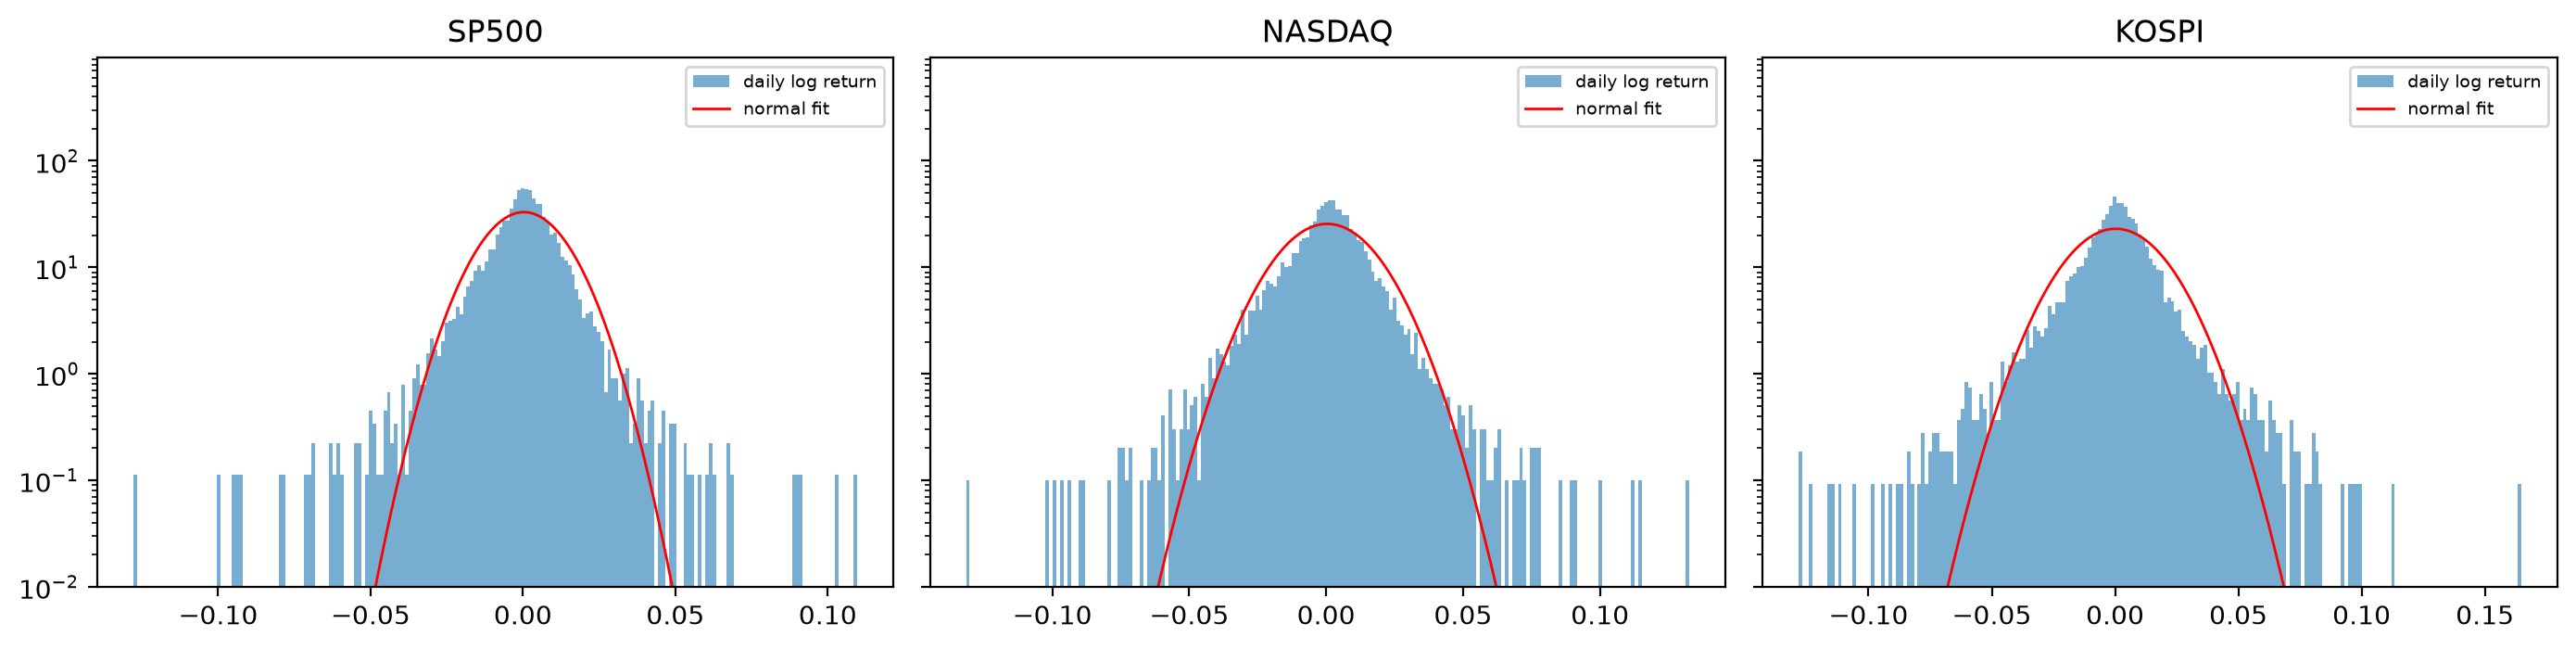

In [12]:
# 수익률 분포: 정규분포보다 꼬리가 두껍고(첨도 > 0) 비대칭인지 확인 -> 분위수를 직접 내는 모델을 쓰는 이유
from scipy.stats import norm
fig, axes = plt.subplots(1, len(data), figsize=(14, 3.6), sharey=True)
stats = {}
for ax, (k, d) in zip(axes, data.items()):
    r = d["r1"].dropna()
    ax.hist(r, bins=200, density=True, alpha=0.6, label="daily log return")
    xs = np.linspace(r.min(), r.max(), 400); ax.plot(xs, norm.pdf(xs, r.mean(), r.std()), "r", lw=1, label="normal fit")
    ax.set_yscale("log"); ax.set_ylim(1e-2); ax.set_title(k); ax.legend(fontsize=7)
    stats[k] = {"skew": r.skew(), "excess_kurtosis": r.kurt(), "q05": r.quantile(0.05), "q95": r.quantile(0.95)}
fig.tight_layout()
pd.DataFrame(stats).T.round(4)

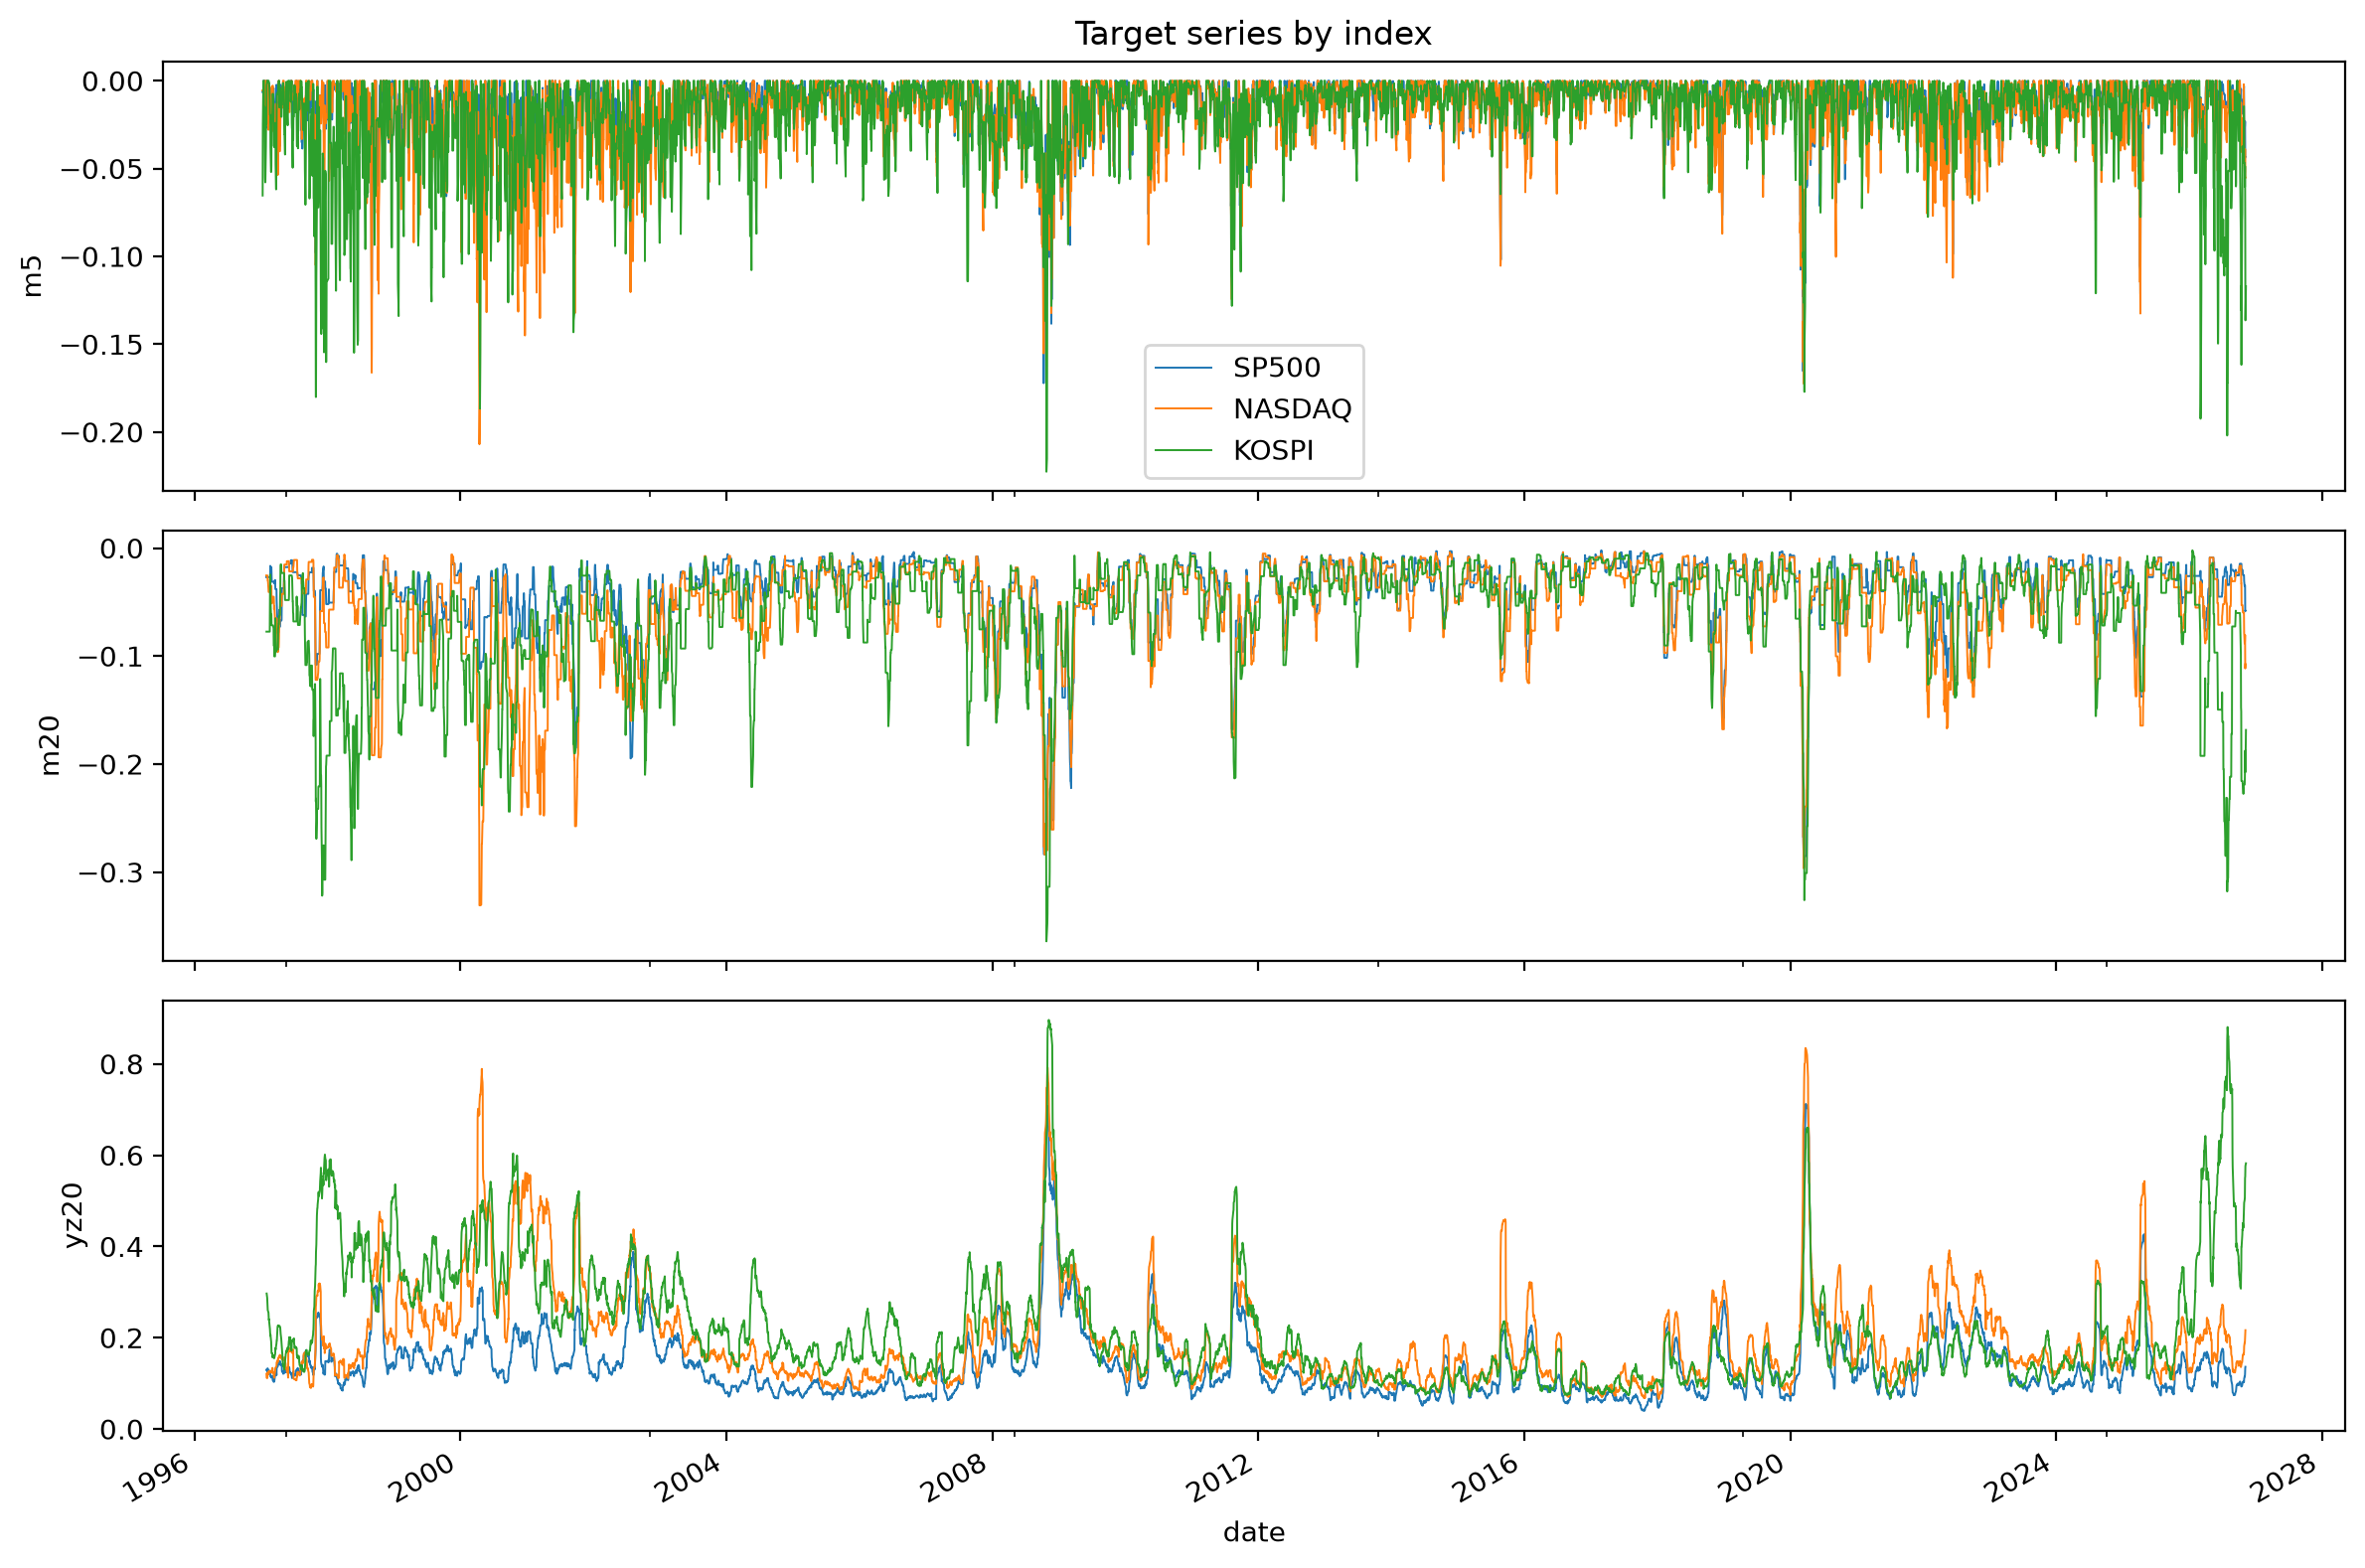

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for k, d in data.items():
    for ax, s in zip(axes, ["m5", "m20", "yz20"]):
        d[s].plot(ax=ax, lw=0.7, label=k); ax.set_ylabel(s)
axes[0].legend(); axes[0].set_title("Target series by index")
fig.tight_layout()